<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Rule matches and string occurrences answer different questions

**Which samples satisfy a ruleset, and what byte-level evidence supports a match?**
We will validate a YARA ruleset, scan a column of small byte inputs, retain missing
and unmatched records, and inspect the individual pattern occurrences behind one
sample's matching rules.

Every sample is authored, inert test data: text markers `ORBIT` and `LANDER`, a
four-byte binary marker, ordinary text, empty bytes and SQL NULL. There are no malware
payloads or observations from a real machine. Rule matches support a scoped review;
they are not a malware verdict or a measure of severity.

## Choose the text rule's condition

`REQUIRE_BOTH_MARKERS=False` accepts either text marker. Setting it to `True` requires
both. The separate binary-marker rule stays unchanged. This boolean changes the
ruleset, not the bytes. Restart and run all after editing it.

In [1]:
REQUIRE_BOTH_MARKERS = False

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_support import finish, prose, theme

if type(REQUIRE_BOTH_MARKERS) is not bool:
    raise ValueError("REQUIRE_BOTH_MARKERS must be True or False.")
audit = hits = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-yara/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-yara/notebooks/pyproject.toml.

## Attach the published release and inventory the bytes

The literal native release location requires no Rust build. Local `read_blob` calls
create one input row per file; a separate NULL row represents an absent sample.
We retain this inventory instead of reconstructing coverage from matching rules.
The worker scans at most the first **64 MiB** of each input. These tiny fixtures all
fit within that bound; a larger input would need an explicit coverage policy.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'yara' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-yara@v0.4.0');
CREATE TABLE inputs AS SELECT regexp_extract(filename,'([^/]+)$',1) AS sample_id,content,
 octet_length(content) AS supplied_bytes FROM read_blob('fixtures/*.bin')
 UNION ALL SELECT 'missing',NULL,NULL;
SELECT sample_id,supplied_bytes,
 least(supplied_bytes,64*1024*1024) AS maximum_scanned_bytes
FROM inputs ORDER BY sample_id;

,sample_id,supplied_bytes,maximum_scanned_bytes
0,binary.bin,6,6
1,both.bin,12,12
2,empty.bin,0,0
3,missing,<NA>,67108864
4,mixed.bin,26,26
5,orbit-only.bin,5,5
6,repeated.bin,14,14
7,unmatched.bin,17,17


## Check rule compilation before scanning data

The visible source below defines two training rules. The first uses `any of them`
or `all of them` according to the parameter; the second matches four literal binary
bytes. `yara_check` returns false for the deliberately broken rule. We retain that
validation result, but only the selected, valid ruleset is passed to the scan calls.
Scanning with invalid rule source would raise an error.

Compilation success establishes syntax and supported features, not detection quality.
For module-dependent rules, inspect `yara.main.yara_modules` to discover the modules
included in this worker build.

In [4]:
%%sql
CREATE TABLE rule_sources AS SELECT * FROM (VALUES
 ('selected',$rules$
rule marker_pair : training {
 strings:
  $orbit = "ORBIT"
  $lander = "LANDER"
 condition:
  {{ 'all' if REQUIRE_BOTH_MARKERS else 'any' }} of them
}
rule binary_marker : training {
 strings:
  $bin = { DE AD BE EF }
 condition:
  $bin
}
$rules$),
 ('invalid','rule broken { condition: }')
) AS r(profile,rule_source);
CREATE TABLE rule_validation AS SELECT *,yara.main.yara_check(rule_source) AS compiles
FROM rule_sources;
SELECT profile,compiles,rule_source FROM rule_validation ORDER BY profile;

,profile,compiles,rule_source
0,invalid,False,rule broken { condition: }
1,selected,True,\nrule marker_pair : training {\n strings:\n ...


In [5]:
assert con.execute("SELECT compiles FROM rule_validation WHERE profile='selected'").fetchone()[0]
# Table functions require constant arguments. Quote the exact validated source and
# selected bytes for the visible table-function SQL below; no scan runs here.
selected_rules = con.execute(
    "SELECT rule_source FROM rule_validation WHERE profile='selected'"
).fetchone()[0]
rules_sql = "'" + selected_rules.replace("'", "''") + "'"
detail_hex = con.execute("SELECT hex(content) FROM inputs WHERE sample_id='mixed.bin'").fetchone()[
    0
]

## Scan the column and retain missingness

The scalar functions accept input and rule columns. Materialize their results once,
then use local SQL to compare them. `yara_match_count` counts matching **rules**, not
pattern occurrences. `yara_first_rule` identifies one matching rule in this release's
iteration order; it is not a priority ranking or a severity score.

NULL input propagates NULL outputs. An empty byte string is a supplied input and
returns a zero count under these rules. A no-match result does not prove safety:
this worker also maps internal scan failures to empty results and does not expose a
separate scan-status flag. We preserve that limitation in the result labels.

In [6]:
%%sql
CREATE TABLE scan_results AS SELECT i.*,
 yara.main.yara_matches(i.content,r.rule_source) AS any_match,
 yara.main.yara_match_count(i.content,r.rule_source) AS matching_rules,
 yara.main.yara_first_rule(i.content,r.rule_source) AS first_rule
FROM inputs i CROSS JOIN rule_validation r WHERE r.profile='selected' AND r.compiles;
CREATE TABLE input_audit AS SELECT sample_id,supplied_bytes,any_match,matching_rules,first_rule,
 CASE WHEN content IS NULL THEN 'Missing input'
 WHEN supplied_bytes=0 THEN 'Empty input, no match'
 WHEN any_match THEN 'Rule match'
 ELSE 'No match reported' END AS result_state
FROM scan_results;
SELECT * FROM input_audit ORDER BY sample_id;

,sample_id,supplied_bytes,any_match,matching_rules,first_rule,result_state
0,binary.bin,6,True,1,binary_marker,Rule match
1,both.bin,12,True,1,marker_pair,Rule match
2,empty.bin,0,False,0,None,"Empty input, no match"
3,missing,<NA>,<NA>,<NA>,None,Missing input
4,mixed.bin,26,True,2,marker_pair,Rule match
5,orbit-only.bin,5,True,1,marker_pair,Rule match
6,repeated.bin,14,True,1,marker_pair,Rule match
7,unmatched.bin,17,False,0,None,No match reported


In [7]:
%%sql audit <<
SELECT * FROM input_audit ORDER BY sample_id;

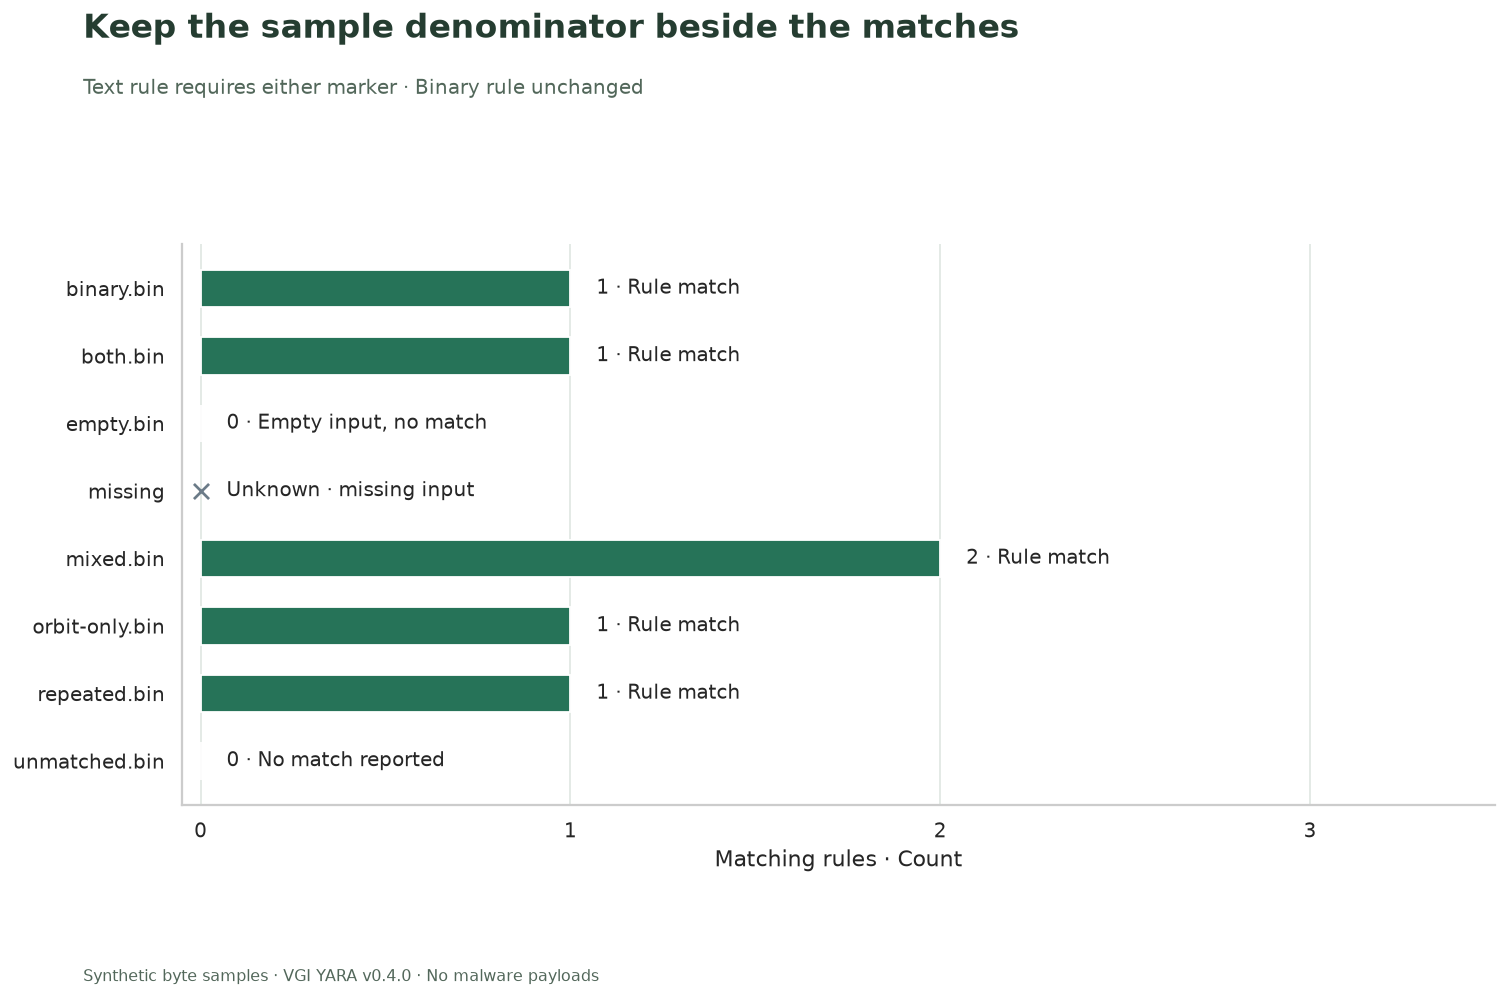

**5 of 7 supplied inputs** report at least one matching rule; one missing input remains unknown. The repeated-marker sample demonstrates that repeating one text pattern does not increase the count of matching rules. A zero is only a no-match report for this ruleset and scan scope.

In [8]:
fig, ax = plt.subplots(figsize=(12, 7.8))
for i, r in enumerate(audit.itertuples()):
    if pd.isna(r.matching_rules):
        ax.scatter(0, i, marker="x", s=70, color="#6b7b88")
        label = "Unknown · missing input"
    else:
        ax.barh(
            i, r.matching_rules, color="#267358" if r.matching_rules > 0 else "#8d9690", height=0.55
        )
        label = f"{int(r.matching_rules)} · {r.result_state}"
    ax.text(
        (0 if pd.isna(r.matching_rules) else r.matching_rules) + 0.07,
        i,
        label,
        va="center",
        fontsize=11,
    )
ax.set_yticks(range(len(audit)), audit.sample_id)
ax.invert_yaxis()
ax.set_xlim(-0.05, max(1, float(audit.matching_rules.max())) + 1.5)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel("Matching rules · Count")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Keep the sample denominator beside the matches",
    f"Text rule requires {'both markers' if REQUIRE_BOTH_MARKERS else 'either marker'} · Binary rule unchanged",
    "01_sample_matches.png",
    bottom=0.11,
)
matched = int(audit.any_match.fillna(False).sum())
present = int(audit.supplied_bytes.notna().sum())
prose(
    f"**{matched} of {present} supplied inputs** report at least one matching rule; one missing input remains unknown. "
    "The repeated-marker sample demonstrates that repeating one text pattern does not increase the count of matching rules. A zero is only a no-match report for this ruleset and scan scope."
)

## Inspect the evidence behind the mixed sample

The mixed sample contains two `ORBIT` occurrences, one `LANDER`, and the binary
marker. Table functions require constant arguments, so a folded preparation cell
quotes the exact validated rules and hex-encodes this already inventoried sample.
The calls remain visible below and are materialized before display. This bridge does
not run a second parser or change the sample bytes.

`yara_scan` gives one row per matching rule with namespace and tags. The string table
reports pattern occurrences **within matching rules**. If a rule condition is false,
its otherwise present patterns do not appear in that table.

In [9]:
%%sql
CREATE TABLE detail_rules AS SELECT * FROM yara.main.yara_scan(
 unhex('{{ detail_hex }}'),{{ rules_sql }});
CREATE TABLE detail_hits AS SELECT * FROM yara.main.yara_string_matches(
 unhex('{{ detail_hex }}'),{{ rules_sql }});
SELECT * FROM detail_rules ORDER BY "rule";

,rule,namespace,tags
0,binary_marker,default,[training]
1,marker_pair,default,[training]


In [10]:
%%sql hits <<
SELECT "rule",identifier,"offset",matched,
 CASE WHEN identifier='$bin' THEN 'Hex rendering' ELSE 'Text rendering' END AS rendering
FROM detail_hits ORDER BY "offset","rule",identifier;

,rule,identifier,offset,matched,rendering
0,marker_pair,$orbit,3,ORBIT,Text rendering
1,marker_pair,$orbit,9,ORBIT,Text rendering
2,marker_pair,$lander,15,LANDER,Text rendering
3,binary_marker,$bin,22,deadbeef,Hex rendering


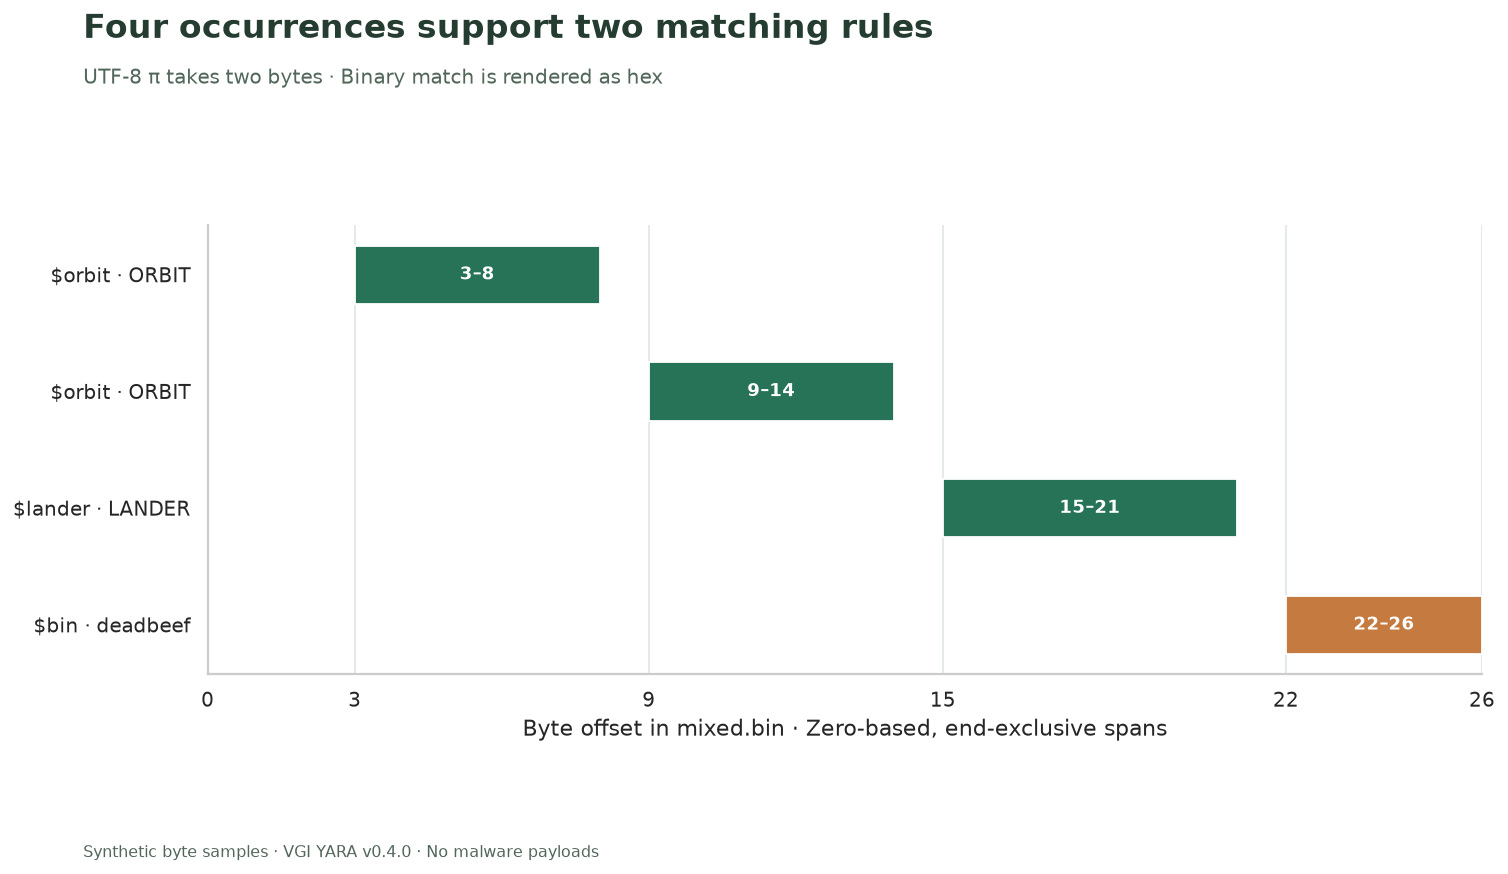

The mixed sample has **2 matching rules and 4 string occurrences**. Its first ORBIT begins at byte **3**, after the two-byte π and a space. The binary occurrence occupies four bytes although its hex rendering has eight characters. The chart uses independently checked fixture pattern lengths, not rendered-string length.

In [11]:
display(hits)
# Known fixture pattern lengths make spans exact. The worker does not return a
# general-purpose match-length field, and its rendered text must not be used as one.
pattern_bytes = {"$orbit": b"ORBIT", "$lander": b"LANDER", "$bin": bytes.fromhex("deadbeef")}
data = bytes.fromhex(detail_hex)
fig, ax = plt.subplots(figsize=(12, 6.8))
for i, r in enumerate(hits.itertuples()):
    # Address the exported offset column by name.
    start = int(hits.iloc[i]["offset"])
    length = len(pattern_bytes[r.identifier])
    assert data[start : start + length] == pattern_bytes[r.identifier]
    color = "#c57b40" if r.identifier == "$bin" else "#267358"
    ax.barh(i, length, left=start, height=0.5, color=color)
    ax.text(
        start + length / 2,
        i,
        f"{start}–{start + length}",
        va="center",
        ha="center",
        color="white",
        fontsize=10,
        weight="bold",
    )
ax.set_yticks(range(len(hits)), [f"{r.identifier} · {r.matched}" for r in hits.itertuples()])
ax.invert_yaxis()
ax.set_xlim(0, len(data))
ax.set_xticks(sorted({0, len(data), *[int(x) for x in hits["offset"]]}))
ax.set_xlabel("Byte offset in mixed.bin · Zero-based, end-exclusive spans")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Four occurrences support two matching rules",
    "UTF-8 π takes two bytes · Binary match is rendered as hex",
    "02_pattern_offsets.png",
    bottom=0.13,
)
rule_count = con.execute("SELECT count(*) FROM detail_rules").fetchone()[0]
prose(
    f"The mixed sample has **{rule_count} matching rules and {len(hits)} string occurrences**. "
    f"Its first ORBIT begins at byte **{int(hits['offset'].min())}**, after the two-byte π and a space. "
    "The binary occurrence occupies four bytes although its hex rendering has eight characters. "
    "The chart uses independently checked fixture pattern lengths, not rendered-string length."
)

## Reconcile rule counts, occurrences and preserved inputs

The checks below cover NULL behavior, selected-rule validity, the unchanged binary
rule, and agreement between scalar and table results for the mixed sample. The
plot code also verifies each reported byte slice against its known fixture pattern.
These checks validate the demonstration, not a threat-detection accuracy claim.

In [12]:
%%sql checks <<
SELECT 'All seven supplied inputs and missing record survive' AS check_name,
 (SELECT count(*)=8 AND count(DISTINCT sample_id)=8 FROM input_audit) AS passed
UNION ALL SELECT 'Selected source compiles and invalid source is retained',
 (SELECT compiles FROM rule_validation WHERE profile='selected')
 AND NOT (SELECT compiles FROM rule_validation WHERE profile='invalid')
UNION ALL SELECT 'Missing input retains NULL scan results',
 (SELECT any_match IS NULL AND matching_rules IS NULL AND first_rule IS NULL FROM input_audit WHERE sample_id='missing')
UNION ALL SELECT 'Empty supplied input is a known zero for these rules',
 (SELECT supplied_bytes=0 AND NOT any_match AND matching_rules=0 FROM input_audit WHERE sample_id='empty.bin')
UNION ALL SELECT 'Predicate and rule count agree on supplied data',
 (SELECT bool_and(any_match=(matching_rules>0)) FROM input_audit WHERE supplied_bytes IS NOT NULL)
UNION ALL SELECT 'First-rule presence agrees with the predicate',
 (SELECT bool_and((first_rule IS NOT NULL)=any_match) FROM input_audit WHERE supplied_bytes IS NOT NULL)
UNION ALL SELECT 'All fixture bytes fit the worker scan bound',
 (SELECT max(supplied_bytes)<64*1024*1024 FROM input_audit)
UNION ALL SELECT 'Single-marker and repeated-marker outcomes follow the condition',
 (SELECT bool_and(any_match=NOT {{ REQUIRE_BOTH_MARKERS }}) FROM input_audit WHERE sample_id IN ('orbit-only.bin','repeated.bin'))
UNION ALL SELECT 'The binary rule remains independent of text condition',
 (SELECT matching_rules=1 AND first_rule='binary_marker' FROM input_audit WHERE sample_id='binary.bin')
UNION ALL SELECT 'Mixed sample scalar count equals table rule count',
 (SELECT matching_rules FROM input_audit WHERE sample_id='mixed.bin')=(SELECT count(*) FROM detail_rules)
UNION ALL SELECT 'Each pattern occurrence belongs to a returned rule',
 NOT EXISTS(SELECT 1 FROM detail_hits h LEFT JOIN detail_rules r ON h."rule"=r."rule" WHERE r."rule" IS NULL)
UNION ALL SELECT 'Four occurrences support two distinct matching rules',
 (SELECT count(*)=4 AND count(DISTINCT "rule")=2 FROM detail_hits);

In [13]:
display(checks)
assert checks.passed.fillna(False).all(), checks.loc[~checks.passed.fillna(False)]
assert (
    int(audit.matching_rules.sum())
    == con.execute("SELECT sum(matching_rules) FROM scan_results").fetchone()[0]
)
prose(
    f"**{len(checks)} SQL checks, four byte-slice checks and the chart reconciliation passed.** "
    "Input coverage and rule evidence remain separate from any operational decision."
)

,check_name,passed
0,All seven supplied inputs and missing record s...,True
1,Selected source compiles and invalid source is...,True
2,Missing input retains NULL scan results,True
3,Empty supplied input is a known zero for these...,True
4,Predicate and rule count agree on supplied data,True
5,First-rule presence agrees with the predicate,True
6,All fixture bytes fit the worker scan bound,True
7,Single-marker and repeated-marker outcomes fol...,True
8,The binary rule remains independent of text co...,True
9,Mixed sample scalar count equals table rule count,True


**12 SQL checks, four byte-slice checks and the chart reconciliation passed.** Input coverage and rule evidence remain separate from any operational decision.

## Experiment: require both text markers

Change **`REQUIRE_BOTH_MARKERS=False` to `True`**, restart and run all. Predict which
samples lose their text-rule match. Compare the first chart and the repeated-marker
row: repeated ORBIT occurrences cannot substitute for a missing LANDER.

The mixed sample contains both text markers, so its two matching rules and four
occurrences should stay unchanged. The binary-only sample should also remain matched.
Input bytes and missingness do not change. This experiment measures a change in
rule logic, not precision, recall or malware prevalence. Reset to **`False`** to
restore the saved example.

In [14]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and provenance](README.md)